# 1. Differentiation matrices: from finite differences to spectral accuracy

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/notebooks/01_differentiation_matrices.ipynb)

*Companion to Chapter 1 of L. N. Trefethen, Spectral Methods in MATLAB (SIAM, 2000).*

Every numerical method for a differential equation needs one basic operation: given the values
of a function at grid points, estimate its derivative there. Any linear rule for doing this is
a matrix, the **differentiation matrix**. This notebook builds a sequence of them, each more
accurate than the last, and follows the sequence to its limit. That limit is a spectral method.

You will see:

- the second- and fourth-order finite difference matrices on a periodic grid
- what happens as the order is raised without limit
- errors that fall to the rounding level with a few dozen grid points
- why the difference is described as "algebraic" against "exponential" convergence

**Worked example:** velocity and acceleration of the piston in a slider-crank mechanism.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import factorial

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## 1.1 The test problem

**Problem.** In a slider-crank mechanism (an engine piston, a reciprocating pump) a crank of
radius $r$ turns through the angle $\theta$ and drives a piston through a connecting rod of
length $l$. The piston position measured from the crank axis is

$$s(\theta) = r\cos\theta + \sqrt{l^2 - r^2\sin^2\theta} .$$

At constant crank speed the piston velocity and acceleration are proportional to $ds/d\theta$
and $d^2s/d\theta^2$.
Suppose $s$ is known only at $N$ equally spaced crank angles. How accurately can the
derivatives be recovered?

The function is smooth and periodic, and its exact derivatives are available for checking.

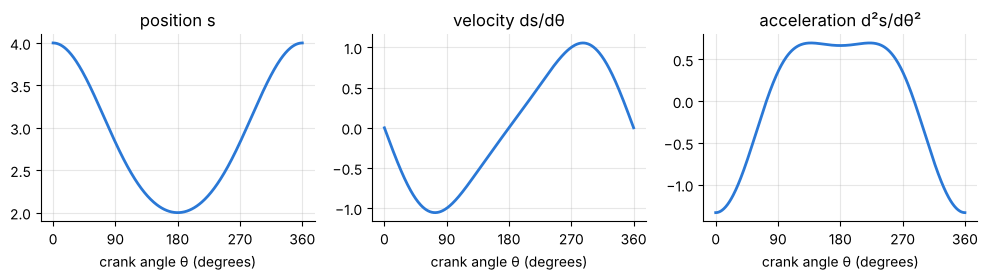

In [2]:
r_crank, l_rod = 1.0, 3.0

def position(theta):
    return r_crank * np.cos(theta) + np.sqrt(l_rod**2 - r_crank**2 * np.sin(theta) ** 2)

def velocity(theta):                        # ds/dθ, exact
    root = np.sqrt(l_rod**2 - r_crank**2 * np.sin(theta) ** 2)
    return -r_crank * np.sin(theta) - r_crank**2 * np.sin(theta) * np.cos(theta) / root

def acceleration(theta):                    # d²s/dθ², exact
    root = np.sqrt(l_rod**2 - r_crank**2 * np.sin(theta) ** 2)
    return (-r_crank * np.cos(theta) - r_crank**2 * np.cos(2 * theta) / root
            - r_crank**4 * np.sin(theta) ** 2 * np.cos(theta) ** 2 / root**3)

fine = np.linspace(0, 2 * np.pi, 400)
fig, axes = plt.subplots(1, 3, figsize=(10, 2.9))
for ax, f, name in zip(axes, (position, velocity, acceleration), ("position s", "velocity ds/dθ", "acceleration d²s/dθ²")):
    ax.plot(np.degrees(fine), f(fine))
    ax.set(xlabel="crank angle θ (degrees)", title=name, xticks=[0, 90, 180, 270, 360])
fig.tight_layout()

The grid has $N$ points $x_j = jh$, $j = 0, \dots, N-1$, with spacing $h = 2\pi/N$. The point
$x_N = 2\pi$ is not stored, because the function repeats there.

## 1.2 Second-order finite differences

**By hand.** The familiar centred formula is

$$u'(x_j) \approx \frac{u_{j+1} - u_{j-1}}{2h} .$$

One way to derive it: pass a parabola through the three points $x_{j-1}, x_j, x_{j+1}$ and
differentiate the parabola at the middle one. Its error is $\tfrac16 h^2 u'''$, so it is
**second-order accurate**.

Applying the formula at every grid point is a matrix-vector product, $\mathbf{w} = D\mathbf{u}$.
Row $j$ of $D$ holds $\tfrac{1}{2h}$ in column $j+1$ and $-\tfrac{1}{2h}$ in column $j-1$.
Because the grid is periodic, the columns wrap around: the neighbours of point 0 are points 1
and $N-1$.

In [3]:
def fd2_matrix(N):
    """Second-order centred difference matrix on a periodic grid of N points."""
    h = 2 * np.pi / N
    D = np.zeros((N, N))
    for j in range(N):
        D[j, (j + 1) % N] = 1 / (2 * h)       # % N makes the indices wrap around
        D[j, (j - 1) % N] = -1 / (2 * h)
    return D

print(np.round(fd2_matrix(6) * (2 * np.pi / 6), 2))      # multiplied by h, to show the pattern

[[ 0.   0.5  0.   0.   0.  -0.5]
 [-0.5  0.   0.5  0.   0.   0. ]
 [ 0.  -0.5  0.   0.5  0.   0. ]
 [ 0.   0.  -0.5  0.   0.5  0. ]
 [ 0.   0.   0.  -0.5  0.   0.5]
 [ 0.5  0.   0.   0.  -0.5  0. ]]


Every row is the row above shifted one place to the right, with wrap-around. Such a matrix is
called **circulant**. All differentiation matrices on a periodic grid have this structure,
because the grid looks the same from every point.

In [4]:
N = 16
x = 2 * np.pi * np.arange(N) / N
error_fd2 = np.abs(fd2_matrix(N) @ position(x) - velocity(x)).max()
print(f"N = {N}: largest error in the velocity = {error_fd2:.2e}")

N = 16: largest error in the velocity = 3.66e-02


Not even two correct digits from 16 points. Better is possible.

## 1.3 Raising the order

The parabola used three points. A polynomial of degree $2m$ through the $2m+1$ points
$x_{j-m}, \dots, x_{j+m}$ gives a formula of order $2m$:

$$u'(x_j) \approx \frac{1}{h}\sum_{k=1}^{m} \alpha_k\,(u_{j+k} - u_{j-k}),\qquad
\alpha_k = \frac{(-1)^{k+1}\,(m!)^2}{k\,(m-k)!\,(m+k)!} .$$

For $m = 1$ this gives $\alpha_1 = \tfrac12$, the formula above. For $m = 2$ it gives
$\alpha_1 = \tfrac23$, $\alpha_2 = -\tfrac1{12}$, the standard fourth-order formula.

In [5]:
def fd_weights(m):
    """Weights α_1..α_m of the centred difference formula of order 2m."""
    return np.array([(-1) ** (k + 1) * factorial(m) ** 2 / (k * factorial(m - k) * factorial(m + k))
                     for k in range(1, m + 1)])

def fd_matrix(N, m):
    """Centred difference matrix of order 2m on a periodic grid of N points."""
    h = 2 * np.pi / N
    D = np.zeros((N, N))
    for k, alpha in enumerate(fd_weights(m), start=1):
        for j in range(N):
            D[j, (j + k) % N] += alpha / h
            D[j, (j - k) % N] -= alpha / h
    return D

assert np.allclose(fd_weights(1), [1 / 2]) and np.allclose(fd_weights(2), [2 / 3, -1 / 12])
assert np.allclose(fd_matrix(12, 1), fd2_matrix(12))

**Verify the orders.** A formula of order $2m$ differentiates polynomials up to degree $2m$
exactly, and its error on a smooth function falls as $h^{2m}$. The cell below tests the second
statement.

In [6]:
def max_error(D, N):
    theta = 2 * np.pi * np.arange(N) / N
    return np.abs(D @ position(theta) - velocity(theta)).max()

for m in (1, 2, 3):
    e_coarse, e_fine = max_error(fd_matrix(32, m), 32), max_error(fd_matrix(64, m), 64)
    observed = np.log2(e_coarse / e_fine)
    print(f"order {2 * m}: error {e_coarse:.1e} at N = 32, {e_fine:.1e} at N = 64, observed order {observed:.2f}")
    assert abs(observed - 2 * m) < 0.4

order 2: error 9.5e-03 at N = 32, 2.4e-03 at N = 64, observed order 1.99
order 4: error 1.8e-04 at N = 32, 1.2e-05 at N = 64, observed order 3.98
order 6: error 7.8e-06 at N = 32, 1.3e-07 at N = 64, observed order 5.90


## 1.4 The limit of infinite order

Why stop? On a periodic grid of $N$ points the stencil can grow until it uses **every** point.
What do the weights become as $m \to \infty$?

In [7]:
print(" k    m = 1     m = 2     m = 4     m = 16    m = 64    (-1)^(k+1)/k")
for k in range(1, 6):
    row = [fd_weights(m)[k - 1] if k <= m else 0.0 for m in (1, 2, 4, 16, 64)]
    print(f"{k:2d} " + "".join(f"{value:10.4f}" for value in row) + f"{(-1) ** (k + 1) / k:12.4f}")

 k    m = 1     m = 2     m = 4     m = 16    m = 64    (-1)^(k+1)/k
 1     0.5000    0.6667    0.8000    0.9412    0.9846      1.0000
 2     0.0000   -0.0833   -0.2000   -0.3922   -0.4699     -0.5000
 3     0.0000    0.0000    0.0381    0.1926    0.2899      0.3333
 4     0.0000    0.0000   -0.0036   -0.0939   -0.1950     -0.2500
 5     0.0000    0.0000    0.0000    0.0429    0.1357      0.2000


The weights tend to $\alpha_k = (-1)^{k+1}/k$: the infinite-order formula on an unbounded grid
is

$$u'(x_j) \approx \frac1h\sum_{k=1}^{\infty} \frac{(-1)^{k+1}}{k}\,(u_{j+k} - u_{j-k}).$$

On a periodic grid the values repeat, $u_{j+k+N} = u_{j+k}$, so all the weights that land on the
same grid point can be added up. The sum of that series has a closed form, and the result is the
**spectral differentiation matrix** for even $N$:

$$D_{ij} = \begin{cases} \tfrac12\,(-1)^{i-j}\cot\dfrac{x_i - x_j}{2}, & i \ne j,\\[1ex] 0, & i = j. \end{cases}$$

Notebook 2 derives the same matrix in a completely different way, by differentiating a
trigonometric interpolant. Here it is the end of the finite difference road.

In [8]:
def fourier_diff_matrix(N):
    """First-derivative matrix for the periodic grid of N points (N even)."""
    if N % 2:
        raise ValueError("N must be even")
    h = 2 * np.pi / N
    k = np.arange(N)[:, None] - np.arange(N)[None, :]          # i - j for every entry
    D = np.zeros((N, N))
    off = k != 0
    D[off] = 0.5 * (-1.0) ** k[off] / np.tan(k[off] * h / 2)
    return D

**Verify the limit claim.** Near the diagonal, where $x_j - x_i = kh$ is small,
$\tfrac12\cot(kh/2) \approx 1/(kh)$, so the entry $k$ places to the right of the diagonal is
close to the infinite-order weight $\alpha_k/h$. And the matrix must differentiate $\sin x$
exactly.

In [9]:
N = 64
h = 2 * np.pi / N
D = fourier_diff_matrix(N)
x = 2 * np.pi * np.arange(N) / N
assert np.allclose(D[0, 1:4] * h, [1, -1 / 2, 1 / 3], rtol=1e-2)        # row 0: the weights of u_1, u_2, u_3 are close to α_1, α_2, α_3
assert np.abs(D @ np.sin(x) - np.cos(x)).max() < 1e-12
assert np.allclose(D, -D.T)                                             # antisymmetric, like every centred formula

print(f"N = 16: largest error in the velocity = {max_error(fourier_diff_matrix(16), 16):.2e}")

N = 16: largest error in the velocity = 5.63e-08


The same 16 points that gave fewer than two digits with the second-order formula now give seven.

## 1.5 Algebraic against exponential convergence

Compare all the methods over a range of $N$.

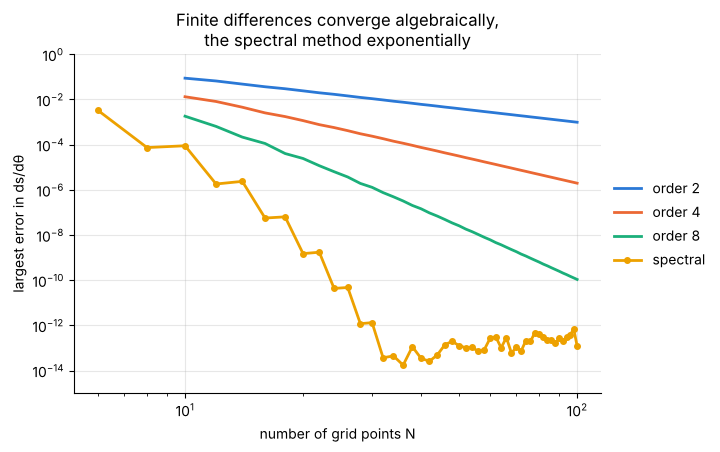

In [10]:
N_values = np.arange(6, 101, 2)
N_fd = N_values[N_values > 8]                                 # the order-8 stencil needs more than 8 points
methods = {"order 2": lambda n: fd_matrix(n, 1), "order 4": lambda n: fd_matrix(n, 2), "order 8": lambda n: fd_matrix(n, 4)}
errors = {name: np.array([max_error(build(n), n) for n in N_fd]) for name, build in methods.items()}
spectral_errors = np.array([max_error(fourier_diff_matrix(n), n) for n in N_values])

fig, ax = plt.subplots(figsize=(6.8, 4.4))
for name, err in errors.items():
    ax.loglog(N_fd, err, label=name)
ax.loglog(N_values, spectral_errors, "o-", ms=4, label="spectral")
ax.set(xlabel="number of grid points N", ylabel="largest error in ds/dθ", ylim=(1e-15, 1),
       title="Finite differences converge algebraically,\nthe spectral method exponentially")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

On these logarithmic axes a finite difference method of order $p$ is a straight line of slope
$-p$: the error behaves like $N^{-p}$. This is **algebraic** convergence.

The spectral curve bends downwards ever more steeply until rounding errors stop it near
$10^{-13}$ from about $N = 32$. Its error behaves like $c^{-N}$ for a constant $c > 1$:
**exponential**, or **spectral**, convergence. It appears as a straight line when only the
vertical axis is logarithmic. (The floor is $10^{-13}$, not $10^{-16}$, because the matrix
entries are of size $N$ and amplify the rounding errors in the data. It rises slowly with $N$.)

In [11]:
decaying = (N_values >= 8) & (N_values <= 34)                 # before rounding errors take over
slope = np.polyfit(N_values[decaying], np.log(spectral_errors[decaying]), 1)[0]
predicted = -np.arccosh(l_rod / r_crank) / 2                  # explained in notebook 3
print(f"fitted decay rate of the error: exp({slope:.2f} N)     predicted: exp({predicted:.2f} N)")
assert abs(slope / predicted - 1) < 0.1 and spectral_errors[N_values == 40][0] < 1e-11

fitted decay rate of the error: exp(-0.88 N)     predicted: exp(-0.88 N)


The fitted rate agrees with the prediction $e^{-0.88N}$. Notebook 3 explains where that number
comes from: it is set by how far $s(\theta)$ can be continued into the complex plane before it
hits a singularity, which here happens where $\sin\theta = l/r$. A longer connecting rod gives
a smoother function and faster convergence.

## 1.6 What accuracy costs

The practical question is how many points are needed for a given accuracy.

In [12]:
def fd_error(N, m):
    """Error of the order-2m formula, applied with shifts instead of a matrix so that N can be large."""
    theta = 2 * np.pi * np.arange(N) / N
    u, h = position(theta), 2 * np.pi / N
    w = sum(alpha * (np.roll(u, -k) - np.roll(u, k)) for k, alpha in enumerate(fd_weights(m), start=1)) / h
    return np.abs(w - velocity(theta)).max()

def points_needed(error_of_N, target, smallest, largest):
    candidates = np.unique(2 * np.round(np.geomspace(smallest, largest, 400) / 2).astype(int))
    return next((int(n) for n in candidates if error_of_N(n) < target), None)

rules = {             # name: (error as a function of N, smallest and largest N tried; the dense spectral matrix stays small)
    "order 2": (lambda n: fd_error(n, 1), 10, 4_000_000), "order 4": (lambda n: fd_error(n, 2), 10, 4_000_000),
    "order 8": (lambda n: fd_error(n, 4), 10, 4_000_000), "spectral": (lambda n: max_error(fourier_diff_matrix(n), n), 6, 200)}
needed = {target: {name: points_needed(rule, target, smallest, largest) for name, (rule, smallest, largest) in rules.items()}
          for target in (1e-3, 1e-6, 1e-9, 1e-11)}

print("approximate number of points needed for an error below the target")
print("target       order 2     order 4     order 8    spectral")
for target, row in needed.items():
    print(f"{target:.0e} " + "".join(f"{'not reached' if n is None else format(n, ','):>12s}" for n in row.values()))
assert needed[1e-11]["spectral"] <= 40 and needed[1e-11]["order 2"] is None

approximate number of points needed for an error below the target
target       order 2     order 4     order 8    spectral
1e-03          100          22          12           8
1e-06        3,156         120          32          16
1e-09      100,340         668          76          24
1e-11  not reached       2,142         138          28


Two things to take from this table.

- At three digits the second-order formula already needs more than ten times as many points as
  the spectral method, and the gap widens quickly: at nine digits it is a factor of four thousand.
  Spectral methods earn their keep when **high accuracy** is wanted, or when memory is the
  limit, as in three-dimensional problems where halving the points per direction saves a factor
  of eight.
- The second-order formula never reaches eleven digits. The grid it would need is so fine that
  rounding errors, which grow like $\varepsilon/h$, exceed the target first.

The price: the spectral matrix is **dense**. Every derivative value depends on every function
value, where the finite difference matrices have only a few non-zeros per row. Notebook 2
removes most of that cost with the fast Fourier transform.

## 1.7 The acceleration

The second derivative can be approximated by applying $D$ twice.

In [13]:
N = 40
x = 2 * np.pi * np.arange(N) / N
D = fourier_diff_matrix(N)
acc_error = np.abs(D @ (D @ position(x)) - acceleration(x)).max()
print(f"largest error in the acceleration with N = {N}: {acc_error:.1e}")
assert acc_error < 1e-10

# largest piston acceleration, which sets the inertia force on the connecting rod
print(f"peak |d²s/dθ²| = {np.abs(D @ D @ position(x)).max():.6f}   exact at θ = 0: {abs(acceleration(0.0)):.6f}")

largest error in the acceleration with N = 40: 3.4e-13
peak |d²s/dθ²| = 1.333333   exact at θ = 0: 1.333333


The peak is at top dead centre and equals $r(1 + r/l) = 4/3$ for these dimensions, the familiar
engine-design formula.

## Summary

- A differentiation rule on a grid is a matrix. On a periodic grid it is circulant.
- Finite difference formulas come from differentiating a **local** polynomial interpolant, and
  converge as $N^{-p}$.
- Letting the stencil cover the whole grid gives a **global** method that converges as
  $c^{-N}$ for smooth functions.
- The cost is a dense matrix, and the benefit is largest at high accuracy.

## Exercises

1. Add the sixth-order formula ($m = 3$) to the convergence plot of 1.5 and confirm its slope.
   At what $N$ does it first beat the fourth-order formula by a factor of 100?
2. Lengthen the connecting rod to $l = 6r$ and repeat the spectral convergence test. How does
   the decay rate change, and how many points now give 12 digits?
3. The spectral matrix was derived for a smooth periodic function. Apply it with $N = 64$ to
   the ramp $u(x) = x$ on $[0, 2\pi)$, whose periodic extension jumps. Plot the result
   against the exact derivative 1 and describe what you see.
4. For $u = \sin(kx)$ the second-order formula returns $\dfrac{\sin(kh)}{h}\cos(kx)$ instead of
   $k\cos(kx)$. Use this to find how many points per wavelength are needed for a 1 % error in
   the derivative, and check your answer numerically. How many does the spectral matrix need?
5. Build the second-derivative matrix from the second-order formula
   $(u_{j+1} - 2u_j + u_{j-1})/h^2$ and compare it with `fd2_matrix(N) @ fd2_matrix(N)`. Are
   they the same matrix? Which is more accurate for the piston acceleration?